# CS231 – Phân loại logo ô tô bằng đặc trưng cạnh và KNN

So sánh Grayscale/RGB và bốn bộ dò cạnh trên VLR-40. Giữ cố định cách tạo vector đặc trưng và KNN để lựa chọn cấu hình theo **validation**.

**Quy trình:** Chia dữ liệu → Trích xuất cạnh → KNN → Validation → Test → Nhận xét.

## 1. Chuẩn bị thư viện

In [1]:
import os
import hashlib
import warnings
from pathlib import Path
from functools import lru_cache

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

SEED = 42
IMAGE_SIZE = 128
K_VALUES = (1, 3, 5, 7)
DETECTORS = ("sobel", "laplacian", "log", "canny")
COLOR_MODES = ("gray", "rgb")
DHASH_DISTANCE = 5

np.random.seed(SEED)
print("OpenCV:", cv2.__version__)
print("KNN: Euclidean, weights='uniform'")

OpenCV: 5.0.0
KNN: Euclidean, weights='uniform'


## 2. Dữ liệu

VLR-40 gồm 40 hãng, mỗi hãng có ảnh train và test riêng. Bài toán chỉ phân loại **ảnh logo đã được cắt sẵn**.

In [2]:
def locate_vlr40():
    custom = os.environ.get("VLR40_ROOT")
    if custom:
        p = Path(custom).expanduser().resolve()
        if (p / "train").is_dir() and (p / "test").is_dir():
            return p
        raise FileNotFoundError(f"VLR40_ROOT không hợp lệ: {p}")

    rel = Path("data/dr233ns3g6-3/VLR-40")
    for base in [Path.cwd(), *Path.cwd().parents]:
        p = base / rel
        if (p / "train").is_dir() and (p / "test").is_dir():
            return p.resolve()
    raise FileNotFoundError(
        "Không tìm thấy VLR-40. Hãy mở notebook từ thư mục project hoặc "
        "đặt VLR40_ROOT=/đường/dẫn/đến/VLR-40 rồi chạy lại."
    )

DATA_ROOT = locate_vlr40()
OUT_DIR = Path.cwd() / "edge_knn_results"
OUT_DIR.mkdir(parents=True, exist_ok=True)

EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
def scan_split(split):
    folder = DATA_ROOT / split
    rows = []
    for p in sorted(folder.rglob("*")):
        if p.is_file() and p.suffix.lower() in EXTENSIONS:
            rows.append({"path": str(p), "label": p.relative_to(folder).parts[0], "split": split})
    return pd.DataFrame(rows)

raw_train = scan_split("train")
raw_test = scan_split("test")
assert not raw_train.empty and not raw_test.empty, "Dữ liệu VLR-40 rỗng."
assert set(raw_train.label) == set(raw_test.label), "Train/test có danh sách nhãn khác nhau."

print("DATA_ROOT:", DATA_ROOT)
print("Train gốc:", len(raw_train), " | Test gốc:", len(raw_test))
print("Số lớp:", raw_train.label.nunique())
print("Số ảnh train theo lớp (min/max):", raw_train.label.value_counts().min(), raw_train.label.value_counts().max())
display(raw_train.head(3))

DATA_ROOT: /home/minhnq/School/CS231/Project/car-logo-cs231-vscode-github/car-logo-cs231/data/dr233ns3g6-3/VLR-40
Train gốc: 2000  | Test gốc: 2000
Số lớp: 40
Số ảnh train theo lớp (min/max): 50 50


,path,label,split
0,/home/minhnq/School/CS231/Project/car-logo-cs2...,Abarth,train
1,/home/minhnq/School/CS231/Project/car-logo-cs2...,Abarth,train
2,/home/minhnq/School/CS231/Project/car-logo-cs2...,Abarth,train


## 3. Kiểm tra ảnh trùng

Dùng SHA-256 và dHash (ngưỡng 5) để phát hiện ảnh trùng/gần trùng. Giữ nguyên test, chỉ loại ảnh tương ứng ở train.

In [ ]:
#Step 1: Read images in grayscale
def get_gray_original(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"Không đọc được: {path}")
    return img
#Step 2: Compute SHA256: Output is a 64-character hexadecimal string representing the hash of the file's contents.
@lru_cache(maxsize=None)
def sha256_file(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()
#Step 3: Compute dHash: 
@lru_cache(maxsize=None)
def dhash(path):
    g = cv2.resize(get_gray_original(path), (9, 8), interpolation=cv2.INTER_AREA)
    bits = (g[:, 1:] > g[:, :-1]).ravel()
    h = 0
    for b in bits:
        h = (h << 1) | int(b)
    return h

train_meta = raw_train.copy()
test_meta = raw_test.copy()
for meta in (train_meta, test_meta):
    meta["sha256"] = [sha256_file(p) for p in meta.path]
    meta["dhash"] = [dhash(p) for p in meta.path]

test_hashes = test_meta.dhash.tolist()
train_meta["min_dhash_to_test"] = [
    min((int(h) ^ int(t)).bit_count() for t in test_hashes)
    for h in train_meta.dhash
]
train_meta["sha_overlap_test"] = train_meta.sha256.isin(set(test_meta.sha256))
train_meta["excluded"] = train_meta.min_dhash_to_test <= DHASH_DISTANCE

excluded = train_meta[train_meta.excluded].copy()
approved_train = train_meta[~train_meta.excluded].copy().reset_index(drop=True)
excluded.to_csv(OUT_DIR / "excluded_train_near_test.csv", index=False)

print("Ảnh train trùng byte với test:", int(train_meta.sha_overlap_test.sum()))
print(f"Ảnh train gần test (dHash <= {DHASH_DISTANCE}), đã loại:", len(excluded))
print("Train còn lại:", len(approved_train), "/", len(train_meta))
print("Test được giữ nguyên:", len(test_meta))
print("Đã lưu danh sách loại:", OUT_DIR / "excluded_train_near_test.csv")
assert approved_train.label.nunique() == raw_train.label.nunique(), "Một lớp bị loại hết ảnh train!"
assert len(approved_train) >= 0.5 * len(raw_train), "Quá nhiều train bị loại, cần kiểm tra ngưỡng dHash."

Ảnh train trùng byte với test: 1
Ảnh train gần test (dHash <= 5), đã loại: 20
Train còn lại: 1980 / 2000
Test được giữ nguyên: 2000
Đã lưu danh sách loại: /home/minhnq/School/CS231/Project/car-logo-cs231-vscode-github/car-logo-cs231/edge_knn_results/excluded_train_near_test.csv


## 4. Chia train/validation

Chia theo nhóm ảnh gần trùng bằng `StratifiedGroupKFold`, giữ các nhóm tách biệt. Test không tham gia chọn tham số.

In [4]:
def assign_near_duplicate_groups(df, threshold=DHASH_DISTANCE):
    groups = [None] * len(df)
    for label, block in df.groupby("label", sort=True):
        positions = block.index.to_list()
        parent = {p: p for p in positions}
        def find(x):
            while parent[x] != x:
                parent[x] = parent[parent[x]]
                x = parent[x]
            return x
        def union(a, b):
            a, b = find(a), find(b)
            if a != b:
                parent[b] = a
        hashes = block.dhash.to_list()
        for i, pi in enumerate(positions):
            for j in range(i + 1, len(positions)):
                if (int(hashes[i]) ^ int(hashes[j])).bit_count() <= threshold:
                    union(pi, positions[j])
        for p in positions:
            groups[p] = f"{label}/{find(p)}"
    return np.array(groups)

approved_train["group"] = assign_near_duplicate_groups(approved_train)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

choices = []
labels_all = set(approved_train.label)
for tr_idx, va_idx in splitter.split(
    approved_train.path, approved_train.label, groups=approved_train.group
):
    tr = approved_train.iloc[tr_idx]
    va = approved_train.iloc[va_idx]
    missing = len(labels_all - set(tr.label)) + len(labels_all - set(va.label))
    proportion_error = abs(len(va) / len(approved_train) - 0.2)
    choices.append((missing, proportion_error, tr_idx, va_idx))

missing, _, train_idx, val_idx = min(choices, key=lambda x: (x[0], x[1]))
assert missing == 0, (
    "Không thể tạo train/validation đủ các lớp với cách nhóm ảnh hiện tại. "
    "Hãy kiểm tra dữ liệu và các nhóm gần trùng, không dùng test để xử lý."
)
train_df = approved_train.iloc[train_idx].reset_index(drop=True)
val_df = approved_train.iloc[val_idx].reset_index(drop=True)
assert set(train_df.group).isdisjoint(set(val_df.group))

manifest = pd.concat([
    train_df.assign(final_split="train"),
    val_df.assign(final_split="val"),
    test_meta.assign(final_split="test")
], ignore_index=True)
manifest.to_csv(OUT_DIR / "split_manifest.csv", index=False)

print(f"Train: {len(train_df)} / Val: {len(val_df)} / Test: {len(test_meta)}")
print("Số lớp ở mỗi tập:", train_df.label.nunique(), val_df.label.nunique(), test_meta.label.nunique())
print("Số nhóm train/val:", train_df.group.nunique(), val_df.group.nunique())

Train: 1584 / Val: 396 / Test: 2000
Số lớp ở mỗi tập: 40 40 40
Số nhóm train/val: 1577 394


## 5. Tiền xử lý và dò cạnh

Resize giữ tỷ lệ về 128×128, phần thiếu được mở rộng từ pixel biên. Với RGB, dò cạnh trên từng kênh rồi lấy phản hồi lớn nhất tại mỗi pixel.

| Phương pháp | Biểu diễn cạnh |
|---|---|
| Sobel | Độ lớn gradient $\sqrt{G_x^2+G_y^2}$ |
| Laplacian | Trị tuyệt đối đạo hàm bậc hai |
| LoG | Gaussian blur rồi lấy trị tuyệt đối Laplacian |
| Canny | Bản đồ cạnh nhị phân |

Mỗi bản đồ cạnh được rút gọn thành **256 đặc trưng**: tổng theo 128 hàng và 128 cột, sau đó chuẩn hóa L2. Canny dùng ngưỡng 100/200; LoG dùng Gaussian 5×5 (σ=1).

In [5]:
@lru_cache(maxsize=6000)
def load_rgb_square(path):
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise ValueError(f"Không đọc được ảnh: {path}")
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    h, w = rgb.shape[:2]
    scale = IMAGE_SIZE / max(h, w)
    new_w = max(1, min(IMAGE_SIZE, int(round(w * scale))))
    new_h = max(1, min(IMAGE_SIZE, int(round(h * scale))))
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    resized = cv2.resize(rgb, (new_w, new_h), interpolation=interp)
    left = (IMAGE_SIZE - new_w) // 2
    right = IMAGE_SIZE - new_w - left
    top = (IMAGE_SIZE - new_h) // 2
    bottom = IMAGE_SIZE - new_h - top
    return cv2.copyMakeBorder(
        resized, top, bottom, left, right, borderType=cv2.BORDER_REPLICATE
    )

def edge_one_channel(channel, detector):
    src = np.ascontiguousarray(channel, dtype=np.uint8)
    if detector == "sobel":
        gx = cv2.Sobel(src, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(src, cv2.CV_32F, 0, 1, ksize=3)
        return cv2.magnitude(gx, gy)
    if detector == "laplacian":
        return np.abs(cv2.Laplacian(src, cv2.CV_32F, ksize=3))
    if detector == "log":
        smooth = cv2.GaussianBlur(src, (5, 5), sigmaX=1.0)
        return np.abs(cv2.Laplacian(smooth, cv2.CV_32F, ksize=3))
    if detector == "canny":
        smooth = cv2.GaussianBlur(src, (5, 5), sigmaX=1.0)
        return cv2.Canny(smooth, 100, 200).astype(np.float32)
    raise ValueError(f"Unknown detector: {detector}")

def edge_map(rgb, color_mode, detector):
    if color_mode == "gray":
        gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
        return edge_one_channel(gray, detector)
    if color_mode == "rgb":
        return np.maximum.reduce([
            edge_one_channel(rgb[:, :, c], detector) for c in range(3)
        ])
    raise ValueError(color_mode)

def edge_feature(edge):
    rows = edge.sum(axis=1, dtype=np.float64)
    cols = edge.sum(axis=0, dtype=np.float64)
    vector = np.concatenate([rows, cols]).astype(np.float32)
    norm = np.linalg.norm(vector)
    return vector / norm if norm > 1e-12 else vector

@lru_cache(maxsize=20000)
def feature(path, mode, detector):
    rgb = load_rgb_square(path)
    return edge_feature(edge_map(rgb, mode, detector))

example_path = train_df.iloc[0].path
for mode in COLOR_MODES:
    for det in DETECTORS:
        f = feature(example_path, mode, det)
        assert f.shape == (2 * IMAGE_SIZE,) and np.isfinite(f).all()
print("Đã kiểm tra 8 cấu hình: mỗi ảnh → vector", 2 * IMAGE_SIZE, "chiều")

Đã kiểm tra 8 cấu hình: mỗi ảnh → vector 256 chiều


### Quan sát ảnh sau xử lý

Đối chiếu ảnh gốc với kết quả dò cạnh. Các đường viền logo và chi tiết nền đều có thể tạo phản hồi.

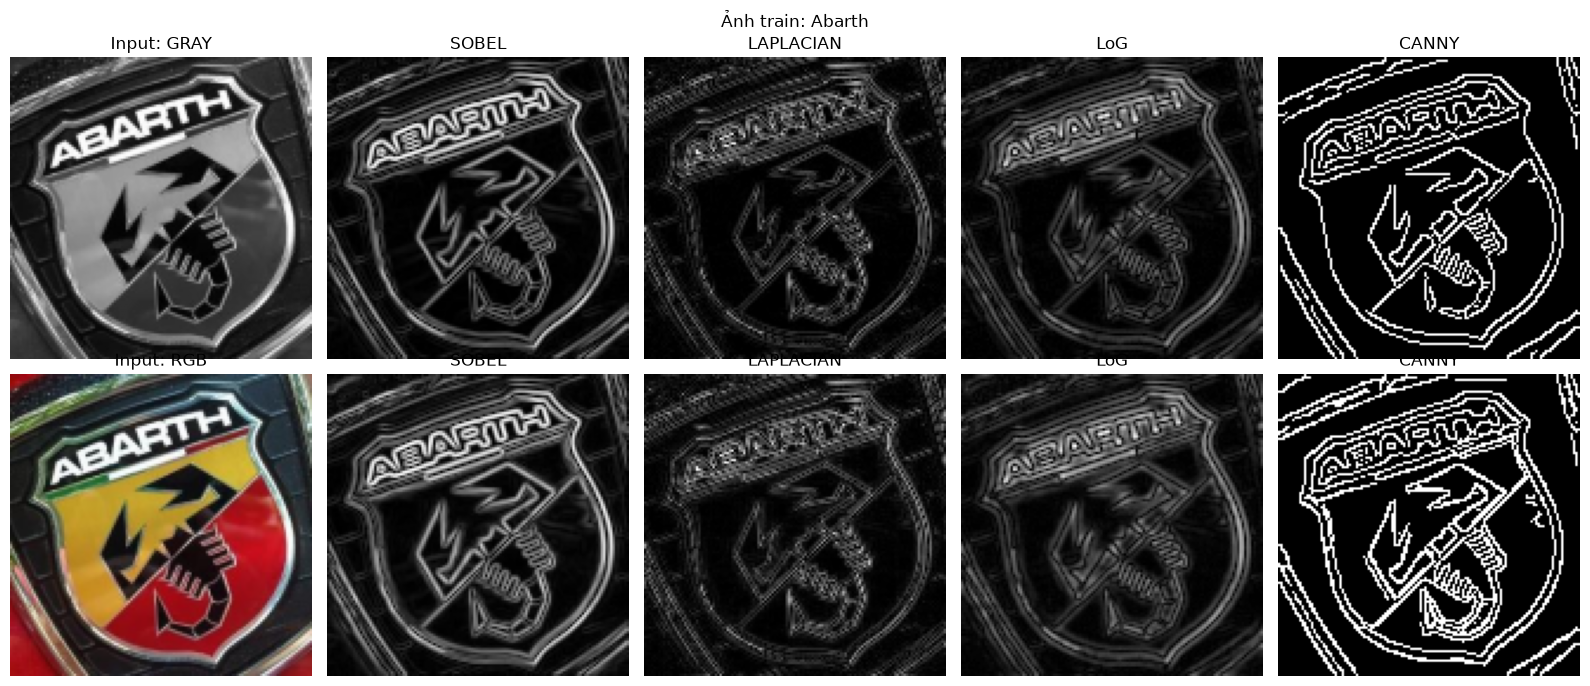

In [6]:
image = load_rgb_square(example_path)
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for r, mode in enumerate(COLOR_MODES):
    axes[r, 0].imshow(image if mode == "rgb" else cv2.cvtColor(image, cv2.COLOR_RGB2GRAY),
                      cmap=None if mode == "rgb" else "gray")
    axes[r, 0].set_title(f"Input: {mode.upper()}")
    axes[r, 0].axis("off")
    for c, detector in enumerate(DETECTORS, start=1):
        em = edge_map(image, mode, detector)
        axes[r, c].imshow(em, cmap="gray")
        axes[r, c].set_title(detector.upper() if detector != "log" else "LoG")
        axes[r, c].axis("off")
plt.suptitle(f"Ảnh train: {train_df.iloc[0].label}")
plt.tight_layout()
plt.show()

## 6. Train và validation

Dùng **KNN (Euclidean, bỏ phiếu đều)** với K = 1, 3, 5, 7. Đánh giá 2 chế độ ảnh × 4 bộ dò cạnh × 4 giá trị K, chọn theo **Macro-F1** (Accuracy dùng khi hòa).

In [7]:
def features_for_df(df, mode, detector):
    return np.stack([
        feature(path, mode, detector) for path in df.path
    ]).astype(np.float32)

train_val_features = {}
records = []
y_train = train_df.label.to_numpy()
y_val = val_df.label.to_numpy()
ALL_LABELS = sorted(raw_train.label.unique())

for mode in COLOR_MODES:
    for det in DETECTORS:
        print(f"Đang đánh giá validation: {mode:4s} / {det:9s}")
        X_train = features_for_df(train_df, mode, det)
        X_val = features_for_df(val_df, mode, det)
        train_val_features[(mode, det)] = (X_train, X_val)
        for k in K_VALUES:
            knn = KNeighborsClassifier(n_neighbors=k, metric="euclidean", weights="uniform")
            knn.fit(X_train, y_train)
            pred = knn.predict(X_val)
            records.append({
                "color_mode": mode,
                "detector": det,
                "k": k,
                "accuracy": accuracy_score(y_val, pred),
                "macro_f1": f1_score(y_val, pred, labels=ALL_LABELS,
                                     average="macro", zero_division=0),
            })

val_results = pd.DataFrame(records)
val_results = val_results.sort_values(
    ["macro_f1", "accuracy", "color_mode", "detector", "k"],
    ascending=[False, False, True, True, True],
).reset_index(drop=True)
val_results.to_csv(OUT_DIR / "validation_all.csv", index=False)

baseline_val = val_results[
    (val_results.color_mode == "gray") &
    (val_results.detector == "sobel") &
    (val_results.k == 3)
].iloc[0]
chosen = val_results.iloc[0]
print("Baseline cố định: gray + sobel + k=3")
print(f"  Macro-F1={baseline_val.macro_f1:.4f}, Accuracy={baseline_val.accuracy:.4f}")
print("Thắng validation:", chosen.color_mode, chosen.detector, "k=", int(chosen.k))
print(f"  Macro-F1={chosen.macro_f1:.4f}, Accuracy={chosen.accuracy:.4f}")
display(val_results)

Đang đánh giá validation: gray / sobel    
Đang đánh giá validation: gray / laplacian
Đang đánh giá validation: gray / log      
Đang đánh giá validation: gray / canny    
Đang đánh giá validation: rgb  / sobel    
Đang đánh giá validation: rgb  / laplacian
Đang đánh giá validation: rgb  / log      
Đang đánh giá validation: rgb  / canny    
Baseline cố định: gray + sobel + k=3
  Macro-F1=0.2995, Accuracy=0.3005
Thắng validation: rgb log k= 7
  Macro-F1=0.3777, Accuracy=0.3763


,color_mode,detector,k,accuracy,macro_f1
0,rgb,log,7,0.376263,0.377655
1,rgb,log,5,0.373737,0.372636
2,rgb,laplacian,1,0.376263,0.369345
3,rgb,laplacian,7,0.363636,0.360144
4,rgb,sobel,7,0.356061,0.357186
5,gray,log,1,0.351010,0.354247
6,gray,laplacian,7,0.361111,0.354228
7,rgb,laplacian,5,0.358586,0.352765
8,gray,laplacian,5,0.353535,0.351424
9,gray,log,7,0.340909,0.350467


## 7. So sánh kết quả validation

Giữ K = 3 để so sánh ảnh xám và RGB, sau đó xem K tốt nhất của từng phương pháp.

### So sánh Grayscale và RGB ở K = 3

In [8]:
fixed_k3 = val_results[val_results.k == 3].copy()
fixed_table = fixed_k3.pivot(index="detector", columns="color_mode", values="macro_f1")
fixed_table["rgb_minus_gray"] = fixed_table["rgb"] - fixed_table["gray"]
print("Validation Macro-F1 (cố định K=3):")
display(fixed_table.round(4))
fixed_table.to_csv(OUT_DIR / "validation_comparison_fixed_k3.csv")

Validation Macro-F1 (cố định K=3):


color_mode,gray,rgb,rgb_minus_gray
detector,,,
canny,0.2713,0.2656,-0.0057
laplacian,0.2908,0.3229,0.0321
log,0.3141,0.3489,0.0348
sobel,0.2995,0.3095,0.0100


,color_mode,detector,k,accuracy,macro_f1
22,gray,canny,1,0.297980,0.302434
6,gray,laplacian,7,0.361111,0.354228
5,gray,log,1,0.351010,0.354247
15,gray,sobel,1,0.333333,0.336109
27,rgb,canny,3,0.275253,0.265644
2,rgb,laplacian,1,0.376263,0.369345
0,rgb,log,7,0.376263,0.377655
4,rgb,sobel,7,0.356061,0.357186


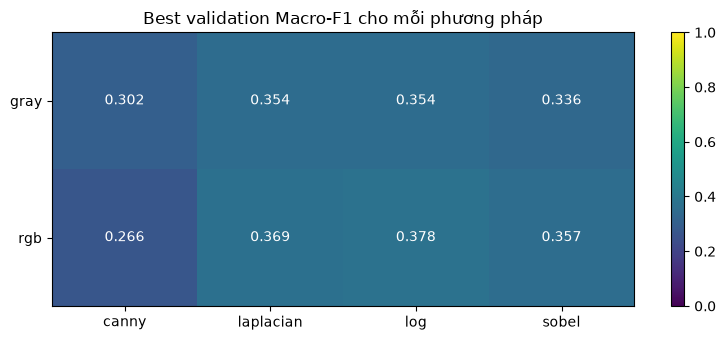

In [9]:
best_per_pair = (
    val_results.sort_values(["macro_f1", "accuracy"], ascending=False)
    .drop_duplicates(["color_mode", "detector"])
    .sort_values(["color_mode", "detector"])
)
display(best_per_pair[["color_mode", "detector", "k", "accuracy", "macro_f1"]])

pivot = best_per_pair.pivot(index="color_mode", columns="detector", values="macro_f1")
fig, ax = plt.subplots(figsize=(8, 3.5))
image_plot = ax.imshow(pivot.to_numpy(), aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(pivot.columns)), pivot.columns)
ax.set_yticks(range(len(pivot.index)), pivot.index)
ax.set_title("Best validation Macro-F1 cho mỗi phương pháp")
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        ax.text(j, i, f"{pivot.iloc[i, j]:.3f}", ha="center", va="center",
                color="white" if pivot.iloc[i, j] < 0.45 else "black")
fig.colorbar(image_plot, ax=ax)
plt.tight_layout()
plt.show()

## 8. Chọn cấu hình và đánh giá test

**Validation chọn RGB + LoG + KNN (K=7)**, Macro-F1 = **0,3777**. Giữ thêm Grayscale + Sobel + KNN (K=3) làm đối chứng ban đầu.


In [10]:
approved_full_train = pd.concat([train_df, val_df], ignore_index=True)
TEST_CONFIGS = [("baseline", "gray", "sobel", 3)]
winning_config = ("selected_on_val", chosen.color_mode, chosen.detector, int(chosen.k))
if winning_config[1:] != TEST_CONFIGS[0][1:]:
    TEST_CONFIGS.append(winning_config)

all_predictions = {}
test_summary = []
y_test = test_meta.label.to_numpy()
y_full = approved_full_train.label.to_numpy()

for tag, mode, det, k in TEST_CONFIGS:
    print(f"TEST (đã chốt): {tag} | {mode}/{det}/k={k}")
    X_full = features_for_df(approved_full_train, mode, det)
    X_test = features_for_df(test_meta, mode, det)
    model = KNeighborsClassifier(n_neighbors=k, metric="euclidean", weights="uniform")
    model.fit(X_full, y_full)
    prediction = model.predict(X_test)
    all_predictions[tag] = prediction
    test_summary.append({
        "config": tag, "color_mode": mode, "detector": det, "k": k,
        "n_test": len(y_test),
        "accuracy": accuracy_score(y_test, prediction),
        "macro_precision": precision_score(y_test, prediction, labels=ALL_LABELS,
                                             average="macro", zero_division=0),
        "macro_recall": recall_score(y_test, prediction, labels=ALL_LABELS,
                                       average="macro", zero_division=0),
        "macro_f1": f1_score(y_test, prediction, labels=ALL_LABELS,
                             average="macro", zero_division=0),
    })
    pd.DataFrame({"path": test_meta.path, "true": y_test, "pred": prediction,
                  "correct": y_test == prediction}).to_csv(
        OUT_DIR / f"test_predictions_{tag}.csv", index=False
    )

summary_df = pd.DataFrame(test_summary)
summary_df.to_csv(OUT_DIR / "test_summary.csv", index=False)
display(summary_df)

TEST (đã chốt): baseline | gray/sobel/k=3
TEST (đã chốt): selected_on_val | rgb/log/k=7


,config,color_mode,detector,k,n_test,accuracy,macro_precision,macro_recall,macro_f1
0,baseline,gray,sobel,3,2000,0.345,0.428556,0.345,0.34395
1,selected_on_val,rgb,log,7,2000,0.395,0.488618,0.395,0.40337


## 9. Xem các trường hợp dự đoán sai

Phần dưới phân tích **đối chứng Grayscale + Sobel**. Dùng confusion matrix và ảnh sai để mô tả hạn chế, chưa coi đó là bằng chứng về nguyên nhân.

              precision    recall  f1-score   support

      Abarth       0.28      0.78      0.41        50
   AlfaRomeo       0.20      0.54      0.29        50
 AstonMartin       0.27      0.64      0.38        50
        Audi       0.37      0.38      0.37        50
         BMW       0.57      0.48      0.52        50
     Bentley       0.45      0.42      0.43        50
     Bugatti       0.39      0.58      0.46        50
    Cadillac       0.27      0.30      0.29        50
   Chevrolet       0.51      0.38      0.44        50
       Dacia       0.36      0.26      0.30        50
     Ferrari       0.24      0.22      0.23        50
        Fiat       0.23      0.46      0.31        50
        Ford       0.23      0.30      0.26        50
       Honda       0.35      0.26      0.30        50
     Huyndai       0.18      0.30      0.22        50
    Infiniti       0.48      0.24      0.32        50
      Jaguar       0.09      0.28      0.14        50
        Jeep       0.54    

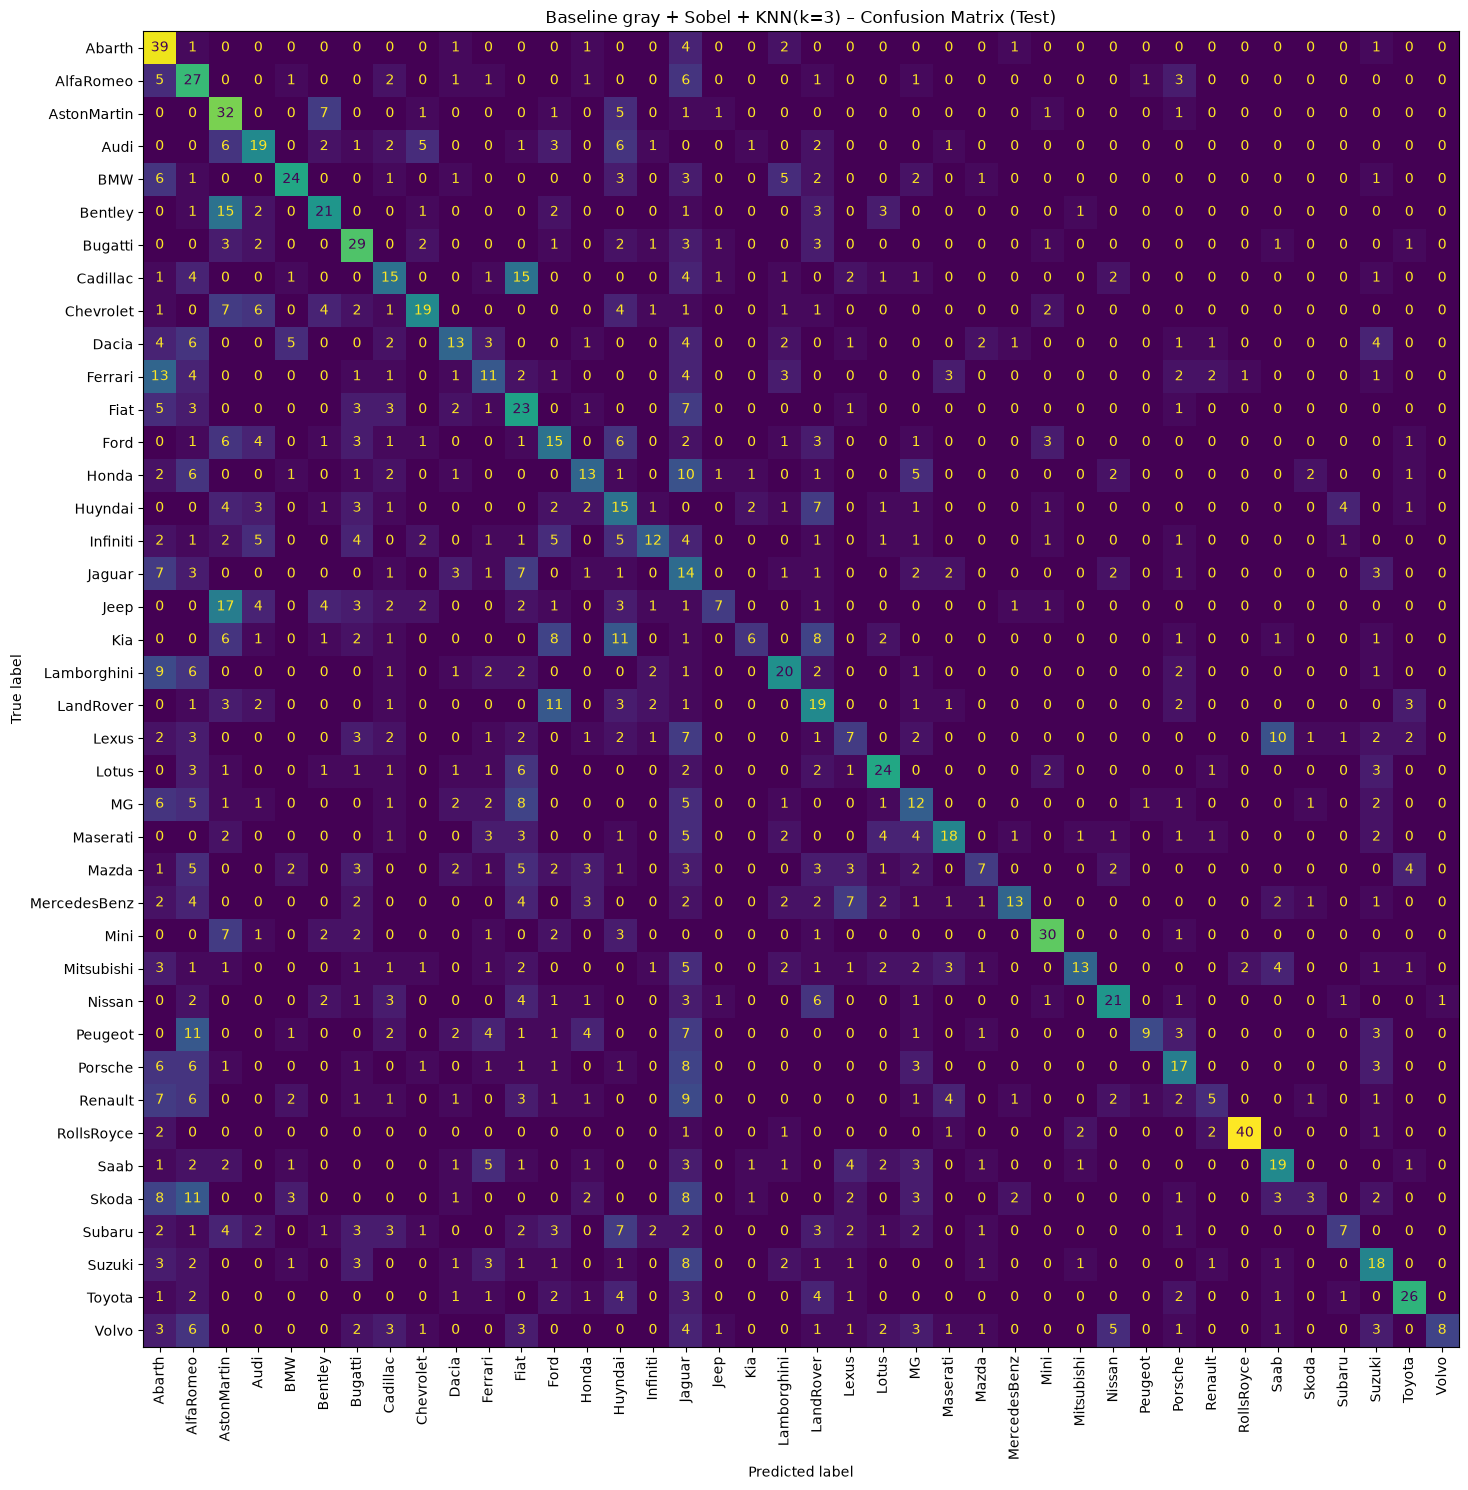

Số ảnh phân loại sai: 1310 / 2000


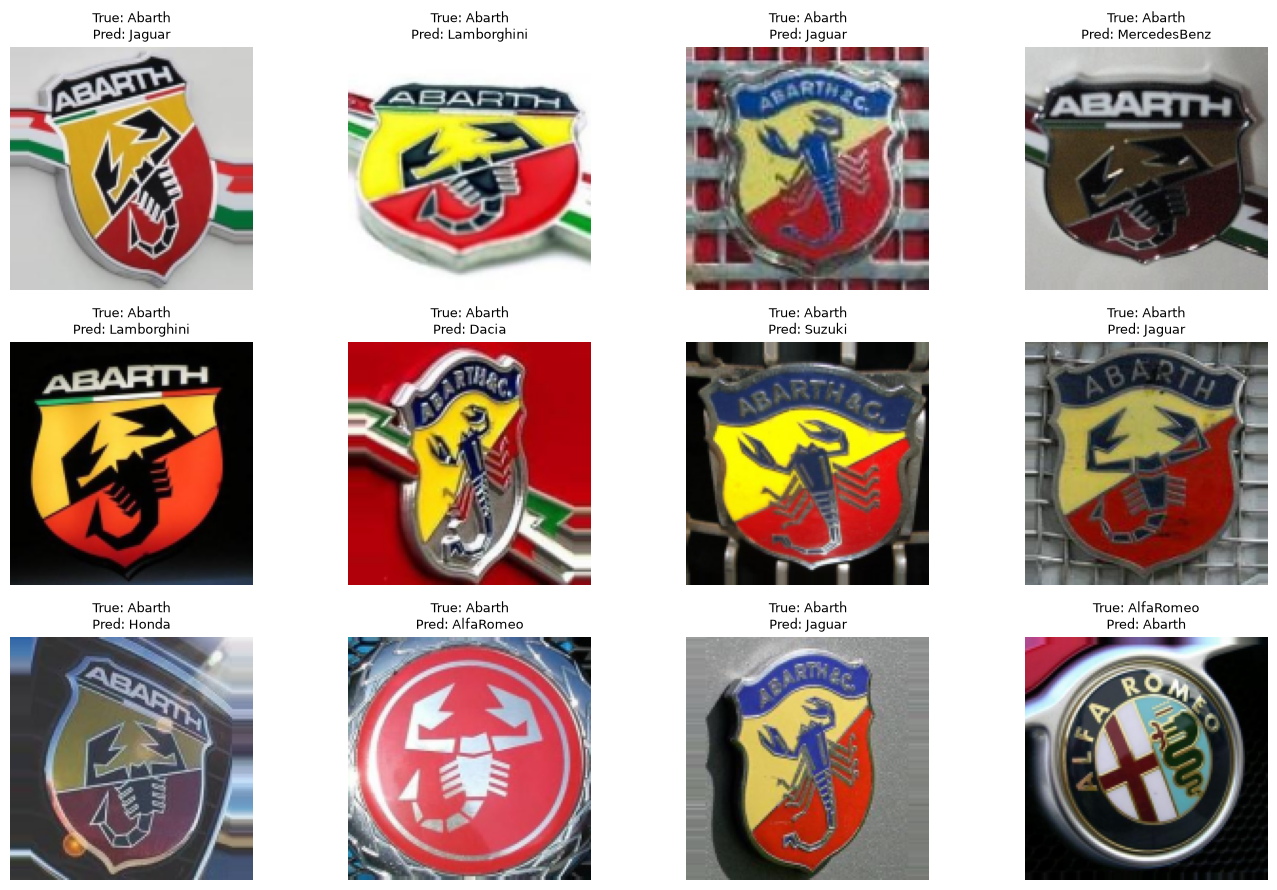

In [11]:
analysis_tag = "baseline"
pred = all_predictions[analysis_tag]
print(classification_report(y_test, pred, labels=ALL_LABELS, zero_division=0))

cm = confusion_matrix(y_test, pred, labels=ALL_LABELS)
fig, ax = plt.subplots(figsize=(17, 15))
ConfusionMatrixDisplay(cm, display_labels=ALL_LABELS).plot(
    ax=ax, xticks_rotation=90, colorbar=False, values_format="d"
)
ax.set_title("Baseline gray + Sobel + KNN(k=3) – Confusion Matrix (Test)")
plt.tight_layout()
plt.savefig(OUT_DIR / "confusion_matrix_baseline.png", dpi=160)
plt.show()

error_indices = np.flatnonzero(pred != y_test)
print("Số ảnh phân loại sai:", len(error_indices), "/", len(y_test))

if len(error_indices):
    examples = error_indices[:min(12, len(error_indices))]
    ncols = 4
    nrows = int(np.ceil(len(examples) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, nrows * 3))
    axes = np.atleast_1d(axes).ravel()
    for j, idx in enumerate(examples):
        axes[j].imshow(load_rgb_square(test_meta.iloc[idx].path))
        axes[j].set_title(f"True: {y_test[idx]}\nPred: {pred[idx]}", fontsize=9)
        axes[j].axis("off")
    for ax in axes[len(examples):]:
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(OUT_DIR / "baseline_errors.png", dpi=140)
    plt.show()

## 10. Kết luận – Baseline được chọn

**Chọn RGB + LoG + KNN (K=7)** làm **baseline chính thức** vì có Macro-F1 cao nhất trên validation.

| Cấu hình | Val Macro-F1 | Test Accuracy | Test Macro-F1 |
|---|---:|---:|---:|
| Đối chứng: Gray + Sobel + KNN (K=3) | 0,2995 | 0,3450 | 0,3440 |
| **Baseline chọn: RGB + LoG + KNN (K=7)** | **0,3777** | **0,3950** | **0,4034** |

Baseline đạt **790/2.000 ảnh đúng** trên test. Kết quả vẫn còn hạn chế với bài toán 40 hãng. Một giả thuyết cần kiểm chứng là phép cộng cạnh theo hàng/cột làm mất thông tin vị trí và cấu trúc đường nét của logo.

**Lưu ý:** Nhánh RGB chỉ dùng phản hồi cạnh trên các kênh màu, không trực tiếp dùng pixel RGB. LoG ở đây dùng $|\nabla^2(G_\sigma * I)|$, không tìm zero-crossing. Test VLR-40 đã từng được sử dụng trong dự án nên không xem đây là kiểm thử hoàn toàn mới ở cấp dự án.

Kết quả chi tiết nằm trong thư mục `edge_knn_results/`. Chưa lựa chọn phương pháp cải tiến ở giai đoạn này.